***CMSC320 Checkpoint 2***

This project aims to analyze the *Inside Airbnb Listings Data -- Washington, D.C., District of Columbia, United States* (https://insideairbnb.com/pt/get-the-data/). We choose this dataset because it is large, has a wide range of uses, and is relevant to the local community of students. It contains both numerical and catergorical attributes, which enable a range of exploratory data analysis capabilities.

**Imports**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

**Data Processing**

In [2]:
# (a) import
listings_df = pd.read_csv("https://data.insideairbnb.com/united-states/dc/washington-dc/2026-09-19/data/listings.csv.gz")

print(f"Shape: {listings_df.shape}")
print(f"Number of listings: {listings_df.shape[0]:,}")
print(f"Number of columns: {listings_df.shape[1]}")

display(listings_df.head(3))


Shape: (6906, 90)
Number of listings: 6,906
Number of columns: 90


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,3344,https://www.airbnb.com/rooms/3344,20260919134059,2026-09-20,previous scrape,"White House-Center City, entire 2BR/2BA Condo","This listing is for full, exclusive-to-the-gue...",NaN,https://a0.muscache.com/pictures/a5261b92-35d9...,4957,...,5.00,5.00,5.00,NaN,NaN,2,2,0,0,0.04
1,3686,https://www.airbnb.com/rooms/3686,20260919134059,2026-09-20,NaN,Vita's Hideaway,IMPORTANT NOTES<br />* Carefully read and be s...,NaN,https://a0.muscache.com/pictures/61e02c7e-3d66...,4645,...,4.84,3.92,4.64,NaN,NaN,1,0,1,0,0.43
2,3943,https://www.airbnb.com/rooms/3943,20260919134059,2026-09-20,NaN,Historic Rowhouse Near Monuments,You will be staying in high ceiling bedroom w...,NaN,https://a0.muscache.com/pictures/airflow/Hosti...,5059,...,4.93,4.63,4.78,Hosted License: 5007242201001033,NaN,6,0,6,0,2.77


In [3]:
# (b) parse

# convert review dates to datetime
listings_df["last_review"] = pd.to_datetime(
    listings_df["last_review"], errors="coerce"
)

listings_df["room_type"] = listings_df["room_type"].astype("category")
listings_df["neighbourhood_cleansed"] = listings_df["neighbourhood_cleansed"].astype("category")

listings_df["price"] = pd.to_numeric(listings_df["price"].str.replace("$", "").str.replace(",", ""), errors="coerce")
listings_df["host_is_superhost"] = listings_df["host_is_superhost"].map({"t": True, "f": False})

In [4]:
# (c) organize

# table summarizing missing values in dataset
missing_summary = pd.DataFrame({
    # missing values in each column
    "missing_count": listings_df.isna().sum(),

    # percentage of missing values in each column
    "missing_percent": listings_df.isna().mean() * 100
})

display(
    missing_summary.sort_values("missing_count", ascending=False)
)

# check for no duplicate listing IDs
print("Duplicate listing IDs:", listings_df["id"].duplicated().sum())

# remove the column containing no information - 'neighbourhood_group'
empty_columns = listings_df.columns[listings_df.isna().all()].to_list()
clean_df = listings_df.drop(columns=empty_columns).copy()

# keep listings with positive/non-zero prices
price_df = clean_df.loc[clean_df["price"] > 0].copy()

# number of listings before filtering by price
print("All listings:", len(clean_df))
print("Listings for price analysis:", len(price_df))

#

,missing_count,missing_percent
host_verifications,6906,100.0
host_total_listings_count,6906,100.0
host_response_time,6906,100.0
host_since,6906,100.0
host_response_rate,6906,100.0
...,...,...
room_type,0,0.0
accommodates,0,0.0
bedrooms,0,0.0
listing_url,0,0.0


Duplicate listing IDs: 0
All listings: 6906
Listings for price analysis: 5993


The dataset contains 6,906 listings with no duplicate listing IDs. We dropped neighbourhood_group because it was entirely missing. For price analyses, we excluded 913 listings with missing prices, leaving 5,993 listings. All listings remain available for analyses that do not require price.

***Data Exploration***

The following is basic data exploration of the dataset as well as some overall summary statistics. This project will explore (1) some basic summary statistics, (2) if "superhosts" are significantly more expensive than other hosts, and (3) if there are significant differences in price between neighborhoods.

**(1)** The following explores some basic summary statistics.

In [5]:
# display statistics of dataset's numerical columns
display(price_df[[
    "price", "minimum_nights", "number_of_reviews",
    "reviews_per_month", "availability_365"
]].describe())

# observe extreme prices
display(price_df.nlargest(10, "price")[["id", "name", "price"]])

# q1, q3 = price_df['price'].quantile([0.25, 0.75])
# iqr = q3 - q1
# upper_bound = q3 + 1.5 * iqr
# print("Outliers: ", (price_df['price'] > upper_bound).sum()) # no. of outliers


,price,minimum_nights,number_of_reviews,reviews_per_month,availability_365
count,5993.000000,5956.000000,5993.000000,4918.000000,5993.000000
mean,317.396092,9.978005,74.627065,1.982588,249.971800
std,1150.663343,19.108063,123.437214,1.982964,107.642314
min,23.940000,1.000000,0.000000,0.010000,0.000000
25%,140.670000,1.000000,2.000000,0.470000,170.000000
50%,213.500000,2.000000,22.000000,1.500000,281.000000
75%,317.000000,14.000000,94.000000,2.940000,343.000000
max,75043.750000,365.000000,1819.000000,29.690000,365.000000


,id,name,price
1558,42068276,Luxury rowhouse w/parking - centrally located,75043.75
6781,1750910821763954256,Steps to Metro Station! Extended-Stay DC Retreat,11709.68
6147,1643665362021979598,5BR DC Home Sleeps 15 | Prime Location,11680.00
6148,1643686227621588137,5BR DC Home Sleeps 14 | Pet-Friendly,11680.00
6149,1644274384334790008,2BR DC Stay w/ King Bed | Sleeps 7,11680.00
6150,1644302681271518979,Huge DC Home Sleeps 21 | Prime Location,11680.00
6153,1645060055644501472,4BR DC Home w/ King Bed + Sleeps 12,11680.00
6154,1645073059526288609,5BR DC Home Sleeps 17 | Prime Location,11680.00
6155,1645083695378140372,Cozy DC Stay | Sleeps 5 | Pet-Friendly,11680.00
6157,1645571714666008058,Spacious DC Home | 5 Baths | Sleeps 11,11680.00


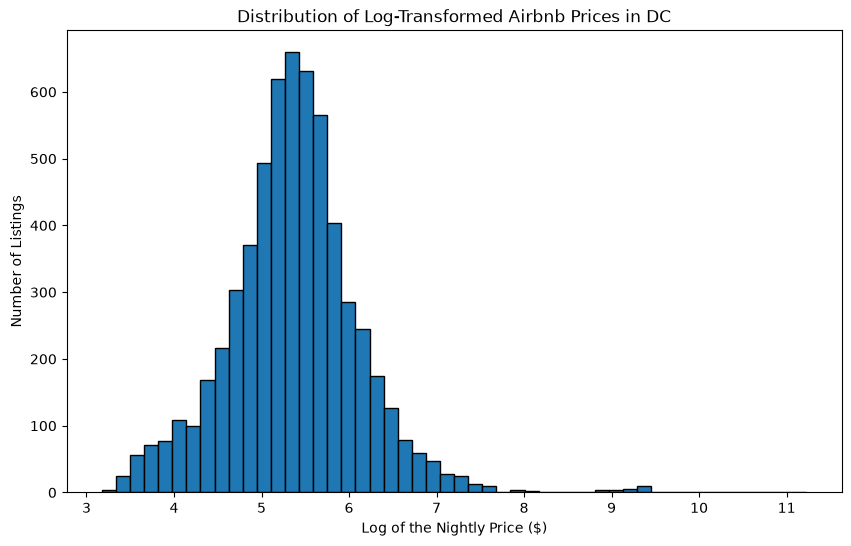

In [28]:
# Histogram of log-transformed prices
plt.figure(figsize = (10, 6))

plt.hist(np.log(price_df["price"]), bins = 50, edgecolor = "black")
plt.title("Distribution of Log-Transformed Airbnb Prices in DC")
plt.xlabel("Log of the Nightly Price ($)")
plt.ylabel("Number of Listings")
plt.show()

***Conclusion:*** The *median nightly price is \$213.50*, compared with a *mean of \$317.40* and a *maximum of \$75,044*, suggesting *right skew*. We retained extreme prices pending further investigation. Missing prices may limit how representative our price analyses are.

**(2)** The following *explores the difference in pricing between "Superhost" and non-Superhosts* by performing a Mann-Whitney U.

We'll perform the following hypothesis test with alpha = 0.05:
>H0: There is no difference in pricing between Superhosts and non-Superhosts.

>Ha: There is a difference in pricing between Superhosts and non-Superhosts.

In [6]:
from scipy.stats import mannwhitneyu

df_mwu = price_df.dropna(subset=['price','host_is_superhost']).copy()

super_prices = df_mwu.loc[df_mwu['host_is_superhost'] == True, "price"]
non_super_prices = df_mwu.loc[df_mwu['host_is_superhost'] == False, "price"]

u_stat, u_p = mannwhitneyu(super_prices, non_super_prices, alternative="two-sided")

print(f"Mann-Whitney U: {u_stat}")
print(f"p-value: {u_p}")

Mann-Whitney U: 4775950.5
p-value: 5.059935582696825e-07


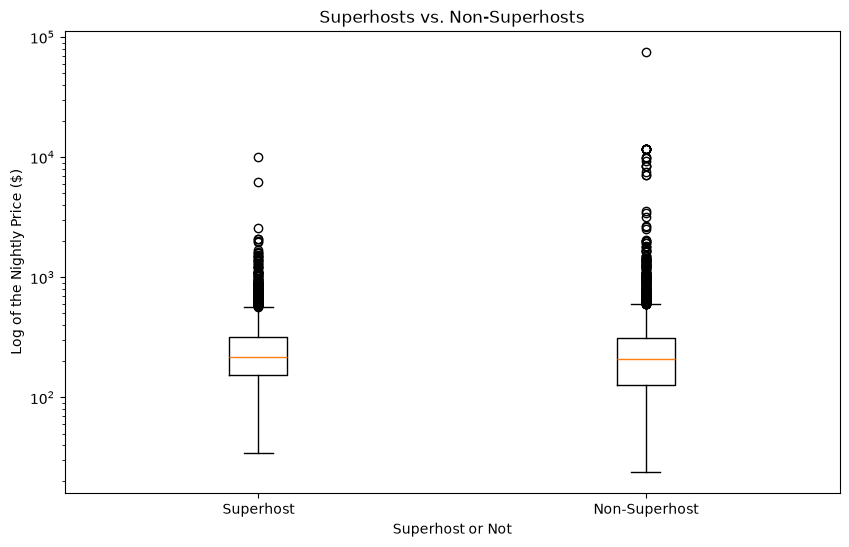

In [ ]:
# Boxplot showing the difference in pricing between "Superhost" and non-Superhosts
plt.figure(figsize = (10, 6))

plt.boxplot([super_prices, non_super_prices], tick_labels = ["Superhost", "Non-Superhost"])
plt.title("Superhosts vs. Non-Superhosts")
plt.xlabel("Superhost or Not")
plt.ylabel("Log of the Nightly Price ($)")
plt.yscale("log")
plt.show()

***Conclusion:*** We found an *essentially zero p-value*, therefore we can *reject the null hypothesis.* There is evidence to suggest the alternative is true, there is a statistically significant difference in pricing between Superhosts and non-Superhosts.

**(3)** The following performs (i) an ANOVA to *determine if price significantly differ across neighborhoods* and (ii) a Turkey's HSD to compare all pairs to *determine the specific neighborhoods with significant price difference*.

We'll perform the following hypothesis test with alpha = 0.05:
>H0: There is no difference in pricing across different neighborhoods.

>Ha: There is at least one difference in pricing across different neighborhoods.

In [59]:
from scipy.stats import f_oneway

df_anova = price_df.dropna(subset=['price','neighbourhood_cleansed']).copy()

counts = df_anova['neighbourhood_cleansed'].value_counts()
print(f"Number of Neighborhoods: {df_anova['neighbourhood_cleansed'].nunique()}")


groups = df_anova.groupby(['neighbourhood_cleansed'], observed=True)['price'].apply(list)

f_stat, f_p = f_oneway(*groups)

print(f"ANOVA F: {f_stat}")
print(f"p-value: {f_p}") # p-val looks rlly high not sure whats wrong

Number of Neighborhoods: 39
ANOVA F: 0.8293938263441043
p-value: 0.7616084557667387


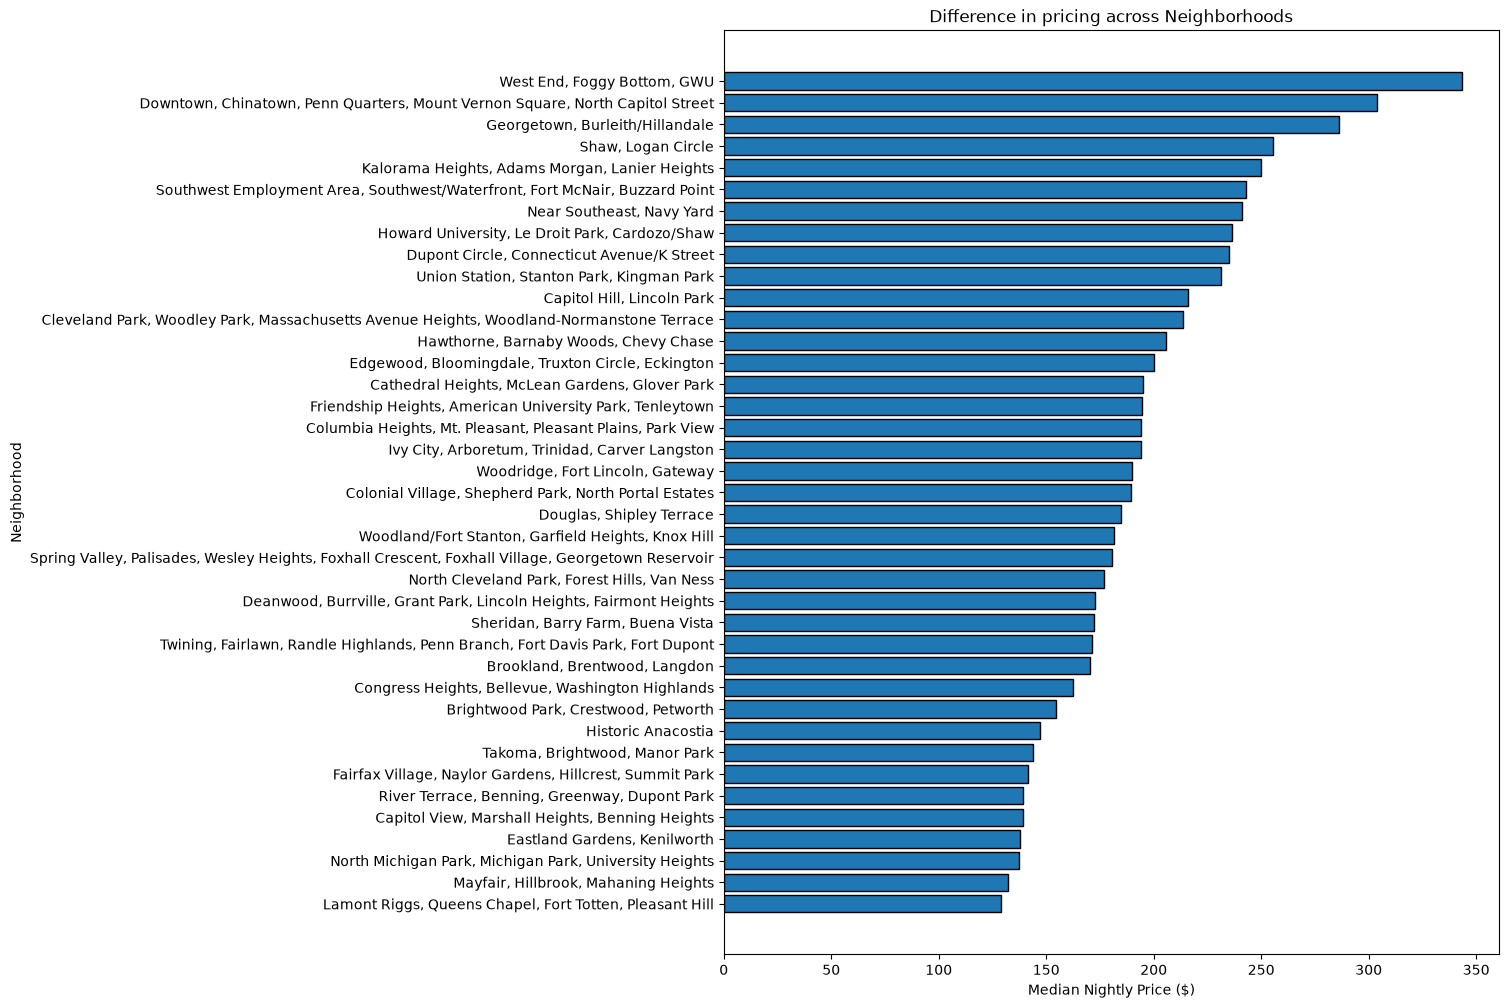

In [71]:
# Bar graph showing the difference in pricing across neighborhoods
plt.figure(figsize = (10, 12))

median_prices = df_anova.groupby('neighbourhood_cleansed', observed = True)['price'].median().sort_values()


plt.barh(median_prices.index, median_prices.values, edgecolor = "black")

plt.title("Difference in pricing across Neighborhoods")
plt.xlabel("Median Nightly Price ($)")
plt.ylabel("Neighborhood")
plt.show()

***Conclusion (pt. 1):*** We found a p-value = 0.76, which is greater than 0.05. We fail to reject our null hypothesis. There is not enough evidence to claim that there is at least one difference in pricing across neighborhoods.

In [ ]:
from scipy.stats import tukey_hsd

tukey = pairwise_tukeyhsd(
    endog = df_anova['price'],
    groups = df_anova['neighbourhood_cleansed'],
    alpha = 0.05
)

print(tukey)

(4) The following performs a Kruskal-Wallis H test to investigate whether Airbnb prices are different depending on the type of room offered.

This test will use an alpha = 0.05:
>H0:  There is no statistically significant difference in Airbnb price distributions across room types.

>Ha: At least one room type has a statistically different price distribution.

In [ ]:
from scipy.stats import kruskal

df_room = price_df.dropna(
    subset = ['price', 'room_type']
).copy()

df_room['price'] = (
    df_room['price']
    .astype(str)
    .str.replace('$', '', regex = False)
    .str.replace(',', '', regex = False)
    .astype(float)
)

print(
    df_room.groupby('room_type')['price']
    .agg(['count','mean','median','std'])
)

groups = [
    group['price'].values
    for room_type, group in df_room.groupby('room_type')
]

#performing kruskal-wallis test:
h_stat, p_val = kruskal(*groups)

print("Kruskal-Wallis H:", h_stat)
print("p-value:", p_val)